In [1]:
!conda install astropy -y

Retrieving notices: done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.0
    latest version: 26.9.1

Please update conda by running

    $ conda update -n base -c conda-forge conda



## Package Plan ##

  environment location: /opt/conda

  added / updated specs:
    - astropy


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    aiobotocore-2.25.2         |     pyhcf101f3_0          79 KB  conda-forge
    aiohappyeyeballs-2.7.1     |     pyhd8ed1ab_0          24 KB  conda-forge
    aiohttp-3.14.4             |  py313h2af15c8_0         1.2 MB  conda-forge
    aioitertools-0.13.0        |     pyhd8ed1ab_0          25 KB  conda-forge
    aiosignal-1.4.0            |     pyhd8ed1ab_0          13 KB  conda-forge
    astropy-8.0.1              |     pyhd8ed1ab_1           9 KB  conda-forge
    a

In [2]:
!conda install ipykernel -y

Channels:
 - conda-forge
Platform: linux-64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.0
    latest version: 26.9.1

Please update conda by running

    $ conda update -n base -c conda-forge conda



## Package Plan ##

  environment location: /opt/conda

  added / updated specs:
    - ipykernel


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ipykernel-7.2.0            |     pyha191276_1         131 KB  conda-forge
    ------------------------------------------------------------
                                           Total:         131 KB

The following packages will be UPDATED:

  ipykernel                              7.1.0-pyha191276_0 --> 7.2.0-pyha191276_1 



                                                                                
Preparing transaction: done
Verifying transaction: done
Executing transaction:

In [3]:
!conda install -c conda-forge ipympl -y

Channels:
 - conda-forge
Platform: linux-64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.0
    latest version: 26.9.1

Please update conda by running

    $ conda update -n base -c conda-forge conda



# All requested packages already installed.



In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.cosmology import FlatLambdaCDM
from scipy.spatial import cKDTree

# import skyproj
# import nessie

In [5]:
from io_cats import read_lens_catalog

In [6]:
cosmo = FlatLambdaCDM(H0=100, Om0=0.3089)

In [7]:
source = Table.read('l768_gr_xyz_27242.fits', memmap=True)

In [8]:
Rv_min, Rv_max = 0.0,100.0
z_min, z_max = 0.10,0.50
delta_min, delta_max = -1.0, 100.0

l = read_lens_catalog(
    'voids_LCDM_09.dat', 
    cat='sparkling', 
    Rv_min=Rv_min, Rv_max=Rv_max, 
    z_min=z_min, z_max=z_max, 
    delta_min=delta_min, 
    delta_max=delta_max
)

print(f'# voids: {len(l.T)}')

# voids: 379107


In [9]:
l = Table(l.T, names=['Rv', 'ra', 'dec', 'redshift', 'xv', 'yv', 'zv', 'rho1', 'delta', 'logp', 'dccm', 'flag'])

In [10]:
l['id'] = np.arange(0,len(l))

In [11]:
lm = l
lm.sort('Rv',reverse=True)
nv = len(lm)

In [12]:
def circle(center, radius, n=50):
    theta = np.linspace(0.0, 2.0*np.pi, n)
    x = radius * np.sin(theta) + center[0]
    y = radius * np.cos(theta) + center[1]
    return x, y

## percolation (fof) with link $\propto$ number density

In [13]:
vol_com = 4*np.pi*(cosmo.comoving_distance(z_max).value**3 - cosmo.comoving_distance(z_min).value**3)
n = len(l)/vol_com
l_mvs = (3/(4*np.pi*n))**(1/3)# mean void separation linking lenght
print(l_mvs)

26.167886876184298


In [14]:
class UnionFind:

    def __init__(self, size):
        self.parent = np.arange(size)
        self.rank = np.zeros(size, dtype=int)

    def find(self, x):

        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]

        return x

    def union(self, x, y):

        root_x = self.find(x)
        root_y = self.find(y)

        if root_x == root_y:
            return

        if self.rank[root_x] < self.rank[root_y]:
            self.parent[root_x] = root_y

        elif self.rank[root_x] > self.rank[root_y]:
            self.parent[root_y] = root_x

        else:
            self.parent[root_y] = root_x
            self.rank[root_x] += 1

In [15]:
def fof_groups(positions, linking_length):
    """
    Find Friends-of-Friends groups in 3D.

    Parameters
    ----------
    positions : array_like
        Array with shape (N, 3).

    linking_length : float
        Maximum separation between linked objects.

    Returns
    -------
    labels : ndarray
        Group ID of each object.
    """

    positions = np.asarray(positions, dtype=float)

    if positions.ndim != 2 or positions.shape[1] != 3:
        raise ValueError("positions must have shape (N, 3)")

    n = len(positions)

    if n == 0:
        return np.empty(0, dtype=int)

    tree = cKDTree(positions)

    pairs = tree.query_pairs(
        linking_length,
        output_type="ndarray",
    )

    uf = UnionFind(n)

    for i, j in pairs:
        uf.union(i, j)

    roots = np.array([
        uf.find(i)
        for i in range(n)
    ])

    _, labels = np.unique(
        roots,
        return_inverse=True,
    )

    return labels


def group_members(labels):
    """Return the object indices belonging to each group."""

    return [
        np.flatnonzero(labels == group_id)
        for group_id in np.unique(labels)
    ]

In [16]:
def fof_voids(positions, radii, linking_factor):
    """
    Friends-of-Friends grouping for spherical voids.

    Two voids i and j are linked when

        distance(i, j) <= linking_factor * (R_i + R_j)

    Parameters
    ----------
    positions : ndarray, shape (N, 3)
        Void centres.

    radii : ndarray, shape (N,)
        Void radii.

    linking_factor : float
        Dimensionless linking parameter.

    Returns
    -------
    labels : ndarray, shape (N,)
        Group ID assigned to each void.
    """

    positions = np.asarray(positions, dtype=float)
    radii = np.asarray(radii, dtype=float)

    if positions.ndim != 2 or positions.shape[1] != 3:
        raise ValueError("positions must have shape (N, 3)")

    if radii.ndim != 1 or len(radii) != len(positions):
        raise ValueError(
            "radii must have shape (N,) and match positions"
        )

    if np.any(radii <= 0):
        raise ValueError("radii must be positive")

    n = len(positions)

    if n == 0:
        return np.empty(0, dtype=int)

    # --------------------------------------------------
    # Find candidate pairs.
    # --------------------------------------------------

    max_radius = np.max(radii)

    max_distance = 2 * linking_factor * max_radius

    tree = cKDTree(positions)

    pairs = tree.query_pairs(
        r=max_distance,
        output_type="ndarray",
    )

    # --------------------------------------------------
    # Union-Find
    # --------------------------------------------------

    uf = UnionFind(n)

    for i, j in pairs:

        distance = np.linalg.norm(
            positions[i] - positions[j]
        )

        linking_distance = linking_factor * (
            radii[i] + radii[j]
        )

        if distance <= linking_distance:
            uf.union(i, j)

    # --------------------------------------------------
    # Convert roots to consecutive group IDs.
    # --------------------------------------------------

    roots = np.array([
        uf.find(i)
        for i in range(n)
    ])

    _, labels = np.unique(
        roots,
        return_inverse=True,
    )

    return labels

### void fof with variable link r1+r2

`linking_factor` valores que se probaron:

|            |                           |                         |                           |
|:----------:|:-------------------------:|:-----------------------:|:-------------------------:|
| linking_factor |           # grupos unimembres          |          # de grupos bimembres         |           maximo de miembros
| 1     | ~379_100 | ... | 2 |
| 1.03  | 230_868 | 36_048 | 22 |
| 1.04  | ... | ... | 33 |
| 1.05  | ... | ... | 47 |
| 1.06  | ... | ... | 70 |
| 1.08  | ~0 | ... | >100 |

- 1: no funciona, no percola y se obtienen grupos de un solo miembro
- 1.03: funciona, maximo de 22 miembros pero gran numero de grupos unimembres (230868)
- 1.04: funciona bien, tiene un maximo de 33 miembros
- 1.05: funciona bien, tiene un maximo de 47 miembros
- 1.06: funciona, pero hay grupos de 70 miembros
- 1.08: no funciona, percola demasiado

In [127]:
%%time
positions = np.column_stack([lm['xv'].data,lm['yv'].data,lm['zv'].data])

labels = fof_voids(
    positions,
    lm['Rv'],
    #linking_factor=1.06, ## works but there are groups with 70 members
    linking_factor=1.03, 
)

groups_factor = group_members(labels)

CPU times: user 1min 51s, sys: 1.77 s, total: 1min 53s
Wall time: 1min 51s


In [128]:
groups_factor

[array([     0,  44614, 151503, 169622, 200701]),
 array([     3,  50606,  95348, 109191, 116112, 171222, 203822, 301818]),
 array([     5,  44178,  48569,  89217, 100178, 157989, 252815, 289404,
        321727, 327679]),
 array([     7,  34380, 148590, 277902, 365036]),
 array([     9,  11290, 257844]),
 array([    10, 263910]),
 array([    11,  45195,  52506,  53830,  63789,  84331,  97577, 242420]),
 array([    12, 140109, 208582, 250364, 251539, 347578]),
 array([    13, 220119]),
 array([    15,  53752,  60888,  75359,  89239, 114357, 175101, 224840,
        284758]),
 array([    16,  56644, 217610, 350040]),
 array([    17,  65905, 234401, 323044, 339944]),
 array([18]),
 array([    19, 112688, 235683]),
 array([    20, 176174]),
 array([    21,  18689,  33983,  49813,  53629,  54880,  69372, 166445,
        228431, 246578, 310830]),
 array([    22, 117864]),
 array([    23, 297681, 345075]),
 array([24]),
 array([    25, 284421]),
 array([    26,  27670,  81214, 115428, 118693, 

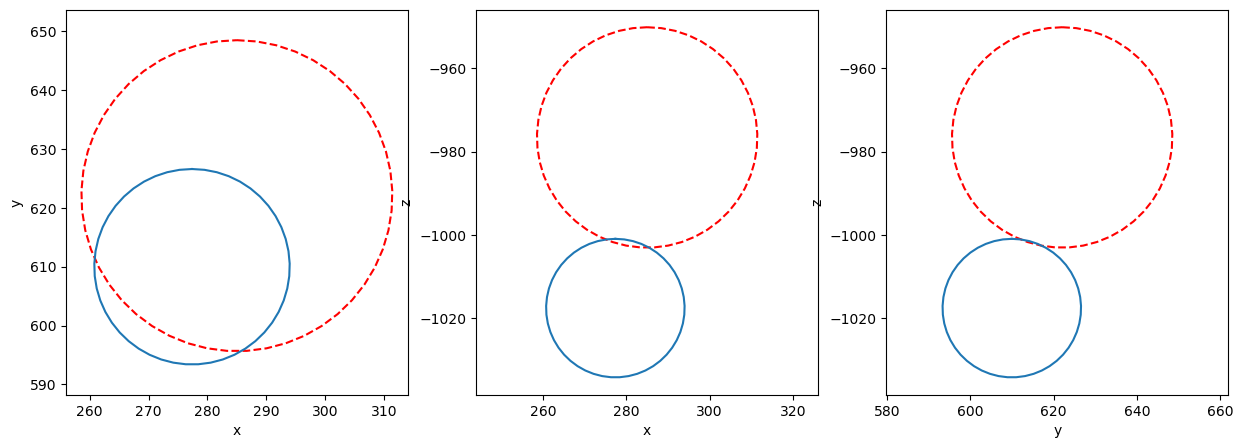

In [129]:
void_group = 31
fig, axes = plt.subplots(1,3,figsize=(15,5))
for i in range(3): axes[i].axis('equal');

axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

axes[1].set_xlabel('x')
axes[1].set_ylabel('z')

axes[2].set_xlabel('y')
axes[2].set_ylabel('z')

# axes[0].scatter(lm['xv'].data[void_id], lm['yv'].data[void_id], s=4, c='r', alpha=0.5)
# axes[1].scatter(lm['xv'].data[void_id], lm['zv'].data[void_id], s=4, c='r', alpha=0.5)
# axes[2].scatter(lm['yv'].data[void_id], lm['zv'].data[void_id], s=4, c='r', alpha=0.5)

for i, li in enumerate(lm[groups_factor[void_group]]):
    radius = li['Rv']
    if i==0:
        axes[0].plot(*circle((li['xv'], li['yv']), radius), c='r', ls='--')
        axes[1].plot(*circle((li['xv'], li['zv']), radius), c='r', ls='--')
        axes[2].plot(*circle((li['yv'], li['zv']), radius), c='r', ls='--')    
        continue
    axes[0].plot(*circle((li['xv'], li['yv']), radius))
    axes[1].plot(*circle((li['xv'], li['zv']), radius))
    axes[2].plot(*circle((li['yv'], li['zv']), radius))

In [130]:
group_multiplicity = np.zeros(len(groups_factor))
for i, gr in enumerate(groups_factor):
    group_multiplicity[i] = len(gr)

mult, count = np.unique(group_multiplicity, return_counts=True)

In [131]:
print(f'# of groups with 1 void: {count[0]}')
print(f'# of groups with 2 void: {count[1]}')
print(f'# of groups with 3 void: {count[2]}')

# of groups with 1 void: 230868
# of groups with 2 void: 36048
# of groups with 3 void: 10952


mean=np.float64(1.3234157529297181)
median=np.float64(1.0)
max_c=np.float64(22.0)


[]

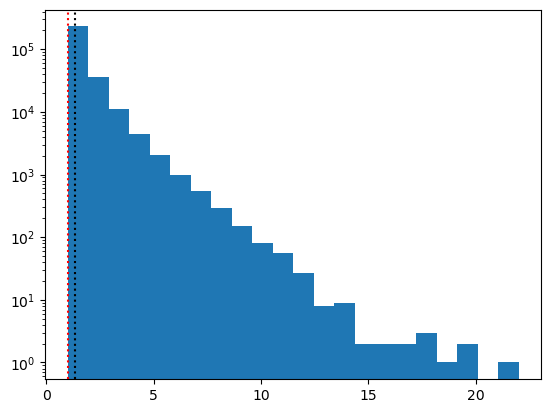

In [132]:
mean = group_multiplicity.mean()
median = np.median(group_multiplicity)
max_c = np.max(group_multiplicity)
print(f'{mean=}')
print(f'{median=}')
print(f'{max_c=}')
plt.hist(group_multiplicity, bins=np.linspace(1,max_c,int(max_c)+1))
plt.axvline(mean, ls=':', c='k')
plt.axvline(median, ls=':', c='r')
plt.semilogy()

### void fof group by fix link

In [77]:
%%time
# positions = np.column_stack([lm['xv'].data,lm['yv'].data,lm['zv'].data])

labels = fof_groups(
    positions,
    1.35*l_mvs,
)

groups_lmsv = group_members(labels)

CPU times: user 4.27 s, sys: 9.66 ms, total: 4.28 s
Wall time: 4.31 s


In [78]:
groups_lmsv

[array([0]),
 array([1]),
 array([2]),
 array([3]),
 array([4]),
 array([5]),
 array([6]),
 array([7]),
 array([8]),
 array([9]),
 array([10]),
 array([11]),
 array([12]),
 array([13]),
 array([14]),
 array([15]),
 array([16]),
 array([17]),
 array([18]),
 array([19]),
 array([20]),
 array([21]),
 array([22]),
 array([23]),
 array([24]),
 array([25]),
 array([26]),
 array([27]),
 array([28]),
 array([29]),
 array([30]),
 array([31]),
 array([32]),
 array([33]),
 array([34]),
 array([35]),
 array([36]),
 array([37]),
 array([38]),
 array([39]),
 array([40]),
 array([41]),
 array([42]),
 array([43]),
 array([45]),
 array([46]),
 array([47]),
 array([48]),
 array([49]),
 array([50]),
 array([51]),
 array([52]),
 array([54]),
 array([55]),
 array([56]),
 array([57]),
 array([58]),
 array([60]),
 array([63]),
 array([65]),
 array([66]),
 array([67]),
 array([69]),
 array([70]),
 array([71]),
 array([74]),
 array([76]),
 array([77]),
 array([79]),
 array([82]),
 array([83]),
 array([87]),
 a

In [42]:
void_group =

lm[groups_lmsv[void_group]]


Rv,ra,dec,redshift,xv,yv,zv,rho1,delta,logp,dccm,flag,id
float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,int64
22.43636,65.512985,-33.14547,0.243875,238.89929,524.5318,-376.3853,-0.904282,-0.087728,-1880.0658,7.126161,2.0,132652


In [ ]:
fig, axes = plt.subplots(1,3,figsize=(15,5))
for i in range(3): axes[i].axis('equal');

axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

axes[1].set_xlabel('x')
axes[1].set_ylabel('z')

axes[2].set_xlabel('y')
axes[2].set_ylabel('z')

# axes[0].scatter(lm['xv'].data[void_id], lm['yv'].data[void_id], s=4, c='r', alpha=0.5)
# axes[1].scatter(lm['xv'].data[void_id], lm['zv'].data[void_id], s=4, c='r', alpha=0.5)
# axes[2].scatter(lm['yv'].data[void_id], lm['zv'].data[void_id], s=4, c='r', alpha=0.5)

for i, li in enumerate(lm[groups_lmvs[void_group]]):
    radius = li['Rv']
    if i==0:
        axes[0].plot(*circle((li['xv'], li['yv']), radius), c='r', ls='--')
        axes[1].plot(*circle((li['xv'], li['zv']), radius), c='r', ls='--')
        axes[2].plot(*circle((li['yv'], li['zv']), radius), c='r', ls='--')    
        continue
    axes[0].plot(*circle((li['xv'], li['yv']), radius))
    axes[1].plot(*circle((li['xv'], li['zv']), radius))
    axes[2].plot(*circle((li['yv'], li['zv']), radius))

## pair distance classification

In [ ]:
d = np.zeros((nv,nv))
dnorm = np.zeros((nv,nv))
idx_flag = []
for i in range(nv):
    for j in range(nv):
        if i>j:
            
            d[i,j] = np.sqrt(
                (lm['xv'].data[i]-lm['xv'].data[j])**2 + (lm['yv'].data[i]-lm['yv'].data[j])**2 + (lm['zv'].data[i]-lm['zv'].data[j])**2
            )
            dnorm[i,j] = d[i,j]/(lm['Rv'][i]+lm['Rv'][j])

            if dnorm[i,j]>0 and dnorm[i,j]<=2:
                idx_flag.append([lm['id'].data[i], lm['id'].data[j]])

In [ ]:
plt.imshow(dnorm)
plt.colorbar()

In [ ]:
flagged_dist = np.where(dnorm>0, np.where(dnorm<=2, 1, 0), 0)
print(f'#flagged={flagged_dist.sum()}')
plt.imshow(flagged_dist)
plt.axline((0,0),slope=1, c='r', alpha=0.5, lw=1)

In [ ]:
void_id = 449325
idx = np.where(lm["id"] == void_id)[0][0]

dist_thr = 1.1
# get neigbours in the same column (smaller than)
mask1 = np.where(dnorm[:,idx]>0.0, np.where(dnorm[:,idx]<dist_thr, True, False), False)
# get neigbours in the same row (bigger than)
mask2 = np.where(dnorm[idx,:]>0.0, np.where(dnorm[idx,:]<dist_thr, True, False), False)
# get neigbours of the smaller ones (row of the mask1 selection)
idx1 = np.where(mask1)[0]
mask3 = np.zeros_like(mask1, dtype=bool)
mask4 = np.zeros_like(mask1, dtype=bool)
for i in idx1:
    mask3 += np.where(dnorm[:,i]>0.0, np.where(dnorm[:,i]<dist_thr, True, False), False)
    mask4 += np.where(dnorm[i,:]>0.0, np.where(dnorm[i,:]<dist_thr, True, False), False)

mask = mask1+mask2+mask3

fix, axes = plt.subplots(1,3,figsize=(15,5))
for i in range(3): axes[i].axis('equal');

axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

axes[1].set_xlabel('x')
axes[1].set_ylabel('z')

axes[2].set_xlabel('y')
axes[2].set_ylabel('z')


axes[0].scatter(lm['xv'].data[idx], lm['yv'].data[idx], s=4, c='r', alpha=0.5)
axes[1].scatter(lm['xv'].data[idx], lm['zv'].data[idx], s=4, c='r', alpha=0.5)
axes[2].scatter(lm['yv'].data[idx], lm['zv'].data[idx], s=4, c='r', alpha=0.5)

axes[0].plot(*circle((lm['xv'].data[idx], lm['yv'].data[idx]),lm['Rv'].data[idx]), c='r', ls='--')
axes[1].plot(*circle((lm['xv'].data[idx], lm['zv'].data[idx]),lm['Rv'].data[idx]), c='r', ls='--')
axes[2].plot(*circle((lm['yv'].data[idx], lm['zv'].data[idx]),lm['Rv'].data[idx]), c='r', ls='--')

# # eps = 7.0
# # width = 0.5
# # m0 = (source['z_gal'].data<lm['zv'].data[idx]+eps)&(source['z_gal'].data>lm['zv'].data[idx]-eps)
# # m1 = (source['y_gal'].data<lm['yv'].data[idx]+eps)&(source['y_gal'].data>lm['yv'].data[idx]-eps)
# # m2 = (source['x_gal'].data<lm['xv'].data[idx]+eps)&(source['x_gal'].data>lm['xv'].data[idx]-eps)
# # axes[0].scatter(source['x_gal'].data[m0], source['y_gal'].data[m0], s=0.5, alpha=0.2)
# # axes[1].scatter(source['x_gal'].data[m1], source['z_gal'].data[m1], s=0.5, alpha=0.2)
# # axes[2].scatter(source['y_gal'].data[m2], source['z_gal'].data[m2], s=0.5, alpha=0.2)

# # axes[0].set_xlim(200,310)
# # axes[1].set_xlim(200,310)
# # axes[0].set_ylim(350,450)
# # axes[2].set_xlim(350,450)
# # axes[1].set_ylim(280,400)
# # axes[2].set_ylim(280,400)

# plt.scatter(lm['xv'].data[mask], lm['yv'].data[mask], s=1, alpha=0.5)

for li in lm[mask]:
    radius = li['Rv']
    axes[0].plot(*circle((li['xv'], li['yv']), radius))
    axes[1].plot(*circle((li['xv'], li['zv']), radius))
    axes[2].plot(*circle((li['yv'], li['zv']), radius))